# Extension 1: Does Kang-style signal persist for documented UCL injury?

**One experimental change:** the broad elbow endpoint becomes the established
documented-UCL endpoint. We preserve the completed Kang replication's 2017–2025
pitcher-game design, season-role strata, predictors, random-game split, R
XGBoost, feature selection, window selection and ROC-AUC procedure.

[Methods and scope](../../docs/kang_ucl_endpoint_methods.md) ·
[Configuration](../../config/kang_ucl_endpoint.yaml)

This notebook reads saved results. It does not fit models or change settings.
The published-method approximations documented in the parent remain in force.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'config/kang_ucl_endpoint.yaml').exists())
R=ROOT/'reports/kang_ucl_endpoint'; T=R/'tables'
display(pd.Series(json.loads((R/'verification.json').read_text())))
display(pd.read_csv(T/'benchmark_equivalence.csv'))

benchmark_hashes_unchanged                                                            True
benchmark_files                                                                       2512
authoritative_endpoint_unchanged                                                      True
database_metadata_unchanged                                                           True
models_refit                                                   [ucl_reliever, ucl_starter]
no_benchmark_refits                                                                   True
identical_R_script                                                                    True
identical_predictors                                                                  True
identical_hyperparameters                                                             True
identical_random_game_split_algorithm                                                 True
chronological_split_used                                                             False

,component,unchanged,evidence
0,version,True,Identical inherited configuration value
1,paper_doi,True,Identical inherited configuration value
2,database,True,Identical inherited configuration value
3,injury_transactions,True,Identical inherited configuration value
4,injury_episode_config,True,Identical inherited configuration value
5,start_date,True,Identical inherited configuration value
6,end_date,True,Identical inherited configuration value
7,game_type,True,Identical inherited configuration value
8,minimum_season_appearances,True,Identical inherited configuration value
9,maximum_season_missing_fraction,True,Identical inherited configuration value


## Endpoint specificity and cohort composition

Use the saved primary adjudication from `ucl_dynamic_endpoint.run_endpoint`,
including official diagnosis or bounded procedure evidence and established QA
exclusions. It is operational documentation, not independent clinical chart review.

Preserve the first combined shoulder/elbow-event rule; add compatible confirmed
UCL forearm presentations to the same event universe. Unsupported elbow cases
are excluded, not moved to healthy controls. Other confirmed UCL episodes outside
the original eligibility/first-event framing remain in the audit, not the model.
The established UCL reference date can precede IL placement; surgery is not onset.

In [2]:
display(pd.read_csv(T/'cohort_comparison.csv'))
display(pd.read_csv(T/'cohort_differences.csv'))
display(pd.read_csv(T/'endpoint_overlap_summary.csv'))
display(pd.read_csv(T/'ucl_source_coverage.csv'))
display(pd.read_csv(T/'cohort_membership_changes.csv'))

,outcome,role,games,pitcher_seasons,unique_pitchers,injury_events,injured_pitchers,control_games,case_games
0,elbow,starter,34477,1665,620,123,106,32975,1502
1,elbow,reliever,119590,3669,1418,233,208,114349,5241
2,ucl,starter,33218,1567,599,36,36,32853,365
3,ucl,reliever,114915,3466,1389,34,34,114304,611


,role,quantity,broad_elbow,ucl,difference
0,starter,games,34477,33218,-1259
1,starter,pitcher_seasons,1665,1567,-98
2,starter,unique_pitchers,620,599,-21
3,starter,injury_events,123,36,-87
4,starter,injured_pitchers,106,36,-70
5,starter,control_games,32975,32853,-122
6,starter,case_games,1502,365,-1137
7,reliever,games,119590,114915,-4675
8,reliever,pitcher_seasons,3669,3466,-203
9,reliever,unique_pitchers,1418,1389,-29


,role,refinement_reason,evidence_category,events
0,reliever,existing_endpoint_QA_exclusion,ambiguous_elbow,1
1,reliever,existing_endpoint_QA_exclusion,broader_elbow,22
2,reliever,existing_endpoint_QA_exclusion,confirmed_official_documentation,5
3,reliever,existing_endpoint_QA_exclusion,confirmed_procedure_supported,5
4,reliever,existing_endpoint_QA_exclusion,probable_supplemental_documentation,3
5,reliever,no_confirmed_UCL_evidence,ambiguous_elbow,16
6,reliever,no_confirmed_UCL_evidence,broader_elbow,149
7,reliever,no_confirmed_UCL_evidence,other_or_unknown_injury,1
8,reliever,no_confirmed_UCL_evidence,probable_supplemental_documentation,1
9,reliever,retained,confirmed_official_documentation,7


,benchmark_mapping_status,initial_injury_region,events
0,added_confirmed_UCL_not_benchmark_elbow,Forearm,15
1,benchmark_pitcher_season_ineligible,Elbow / UCL,56
2,benchmark_pitcher_season_ineligible,Forearm,7
3,benchmark_pitcher_season_ineligible,Unknown / Unspecified,2
4,earlier_broad_shoulder_elbow_or_UCL_event,Elbow / UCL,9
5,earlier_broad_shoulder_elbow_or_UCL_event,Forearm,2
6,no_eligible_pre_reference_games,Elbow / UCL,3
7,outside_regular_season_placement_or_no_placement,Elbow / UCL,1
8,retained_benchmark_elbow,Elbow / UCL,55


,role,benchmark_control_games,ucl_control_games,newly_added_control_games,former_control_games_in_promoted_UCL_seasons,promoted_UCL_events,retained_case_rows_with_changed_lead_days
0,starter,32975,32853,0,122,11,85
1,reliever,114349,114304,0,45,4,257


## Class composition and available event support

The 30-day table compares a shared, already-existing candidate window. It is
descriptive, not a new selection rule. The complete table retains every window.
Technical five-fold support does not mean sufficient independent events for
stable ranks or precisely located optimal windows.

In [3]:
display(pd.read_csv(T/'common_30_day_prevalence.csv'))
display(pd.read_csv(T/'window_support.csv'))
display(pd.read_csv(T/'preflight_support.csv').query('window in [7, 30, 49]'))

,outcome,role,games,positive_games,negative_games,prevalence,represented_events
0,elbow,starter,34477,552,33925,0.016011,120
1,elbow,reliever,119590,1916,117674,0.016021,230
2,ucl,starter,33218,186,33032,0.005599,36
3,ucl,reliever,114915,285,114630,0.002480,34


,outcome,role,window,games,positive_games,negative_games,control_games,earlier_case_negative_games,prevalence,represented_events
0,elbow,starter,7,34477,149,34328,32975,1353,0.004322,112
1,elbow,starter,8,34477,167,34310,32975,1335,0.004844,116
2,elbow,starter,9,34477,191,34286,32975,1311,0.005540,117
3,elbow,starter,10,34477,205,34272,32975,1297,0.005946,117
4,elbow,starter,11,34477,219,34258,32975,1283,0.006352,117
...,...,...,...,...,...,...,...,...,...,...
167,ucl,reliever,45,114915,353,114562,114304,258,0.003072,34
168,ucl,reliever,46,114915,353,114562,114304,258,0.003072,34
169,ucl,reliever,47,114915,357,114558,114304,254,0.003107,34
170,ucl,reliever,48,114915,362,114553,114304,249,0.003150,34


,role,window,train_games,test_games,train_positive_games,test_positive_games,train_events,test_events,supported
0,starter,7,22255,10963,42,19,27,16,True
23,starter,30,22255,10963,123,63,35,32,True
42,starter,49,22255,10963,171,85,36,34,True
43,reliever,7,76992,37923,58,34,30,24,True
66,reliever,30,76992,37923,195,90,34,33,True
85,reliever,49,76992,37923,245,122,34,33,True


## Window-selection behavior

Points show mean training CV AUC; lines are the unchanged `mgcv` smoother.
Shading marks actual qualifying derivative-band segments; dotted lines mark
rounded envelope midpoints. Bands are not confidence intervals or biological
progression timelines. A disconnected band is not a unique optimum.
No maximum-AUC fallback or endpoint-specific tuning is allowed.

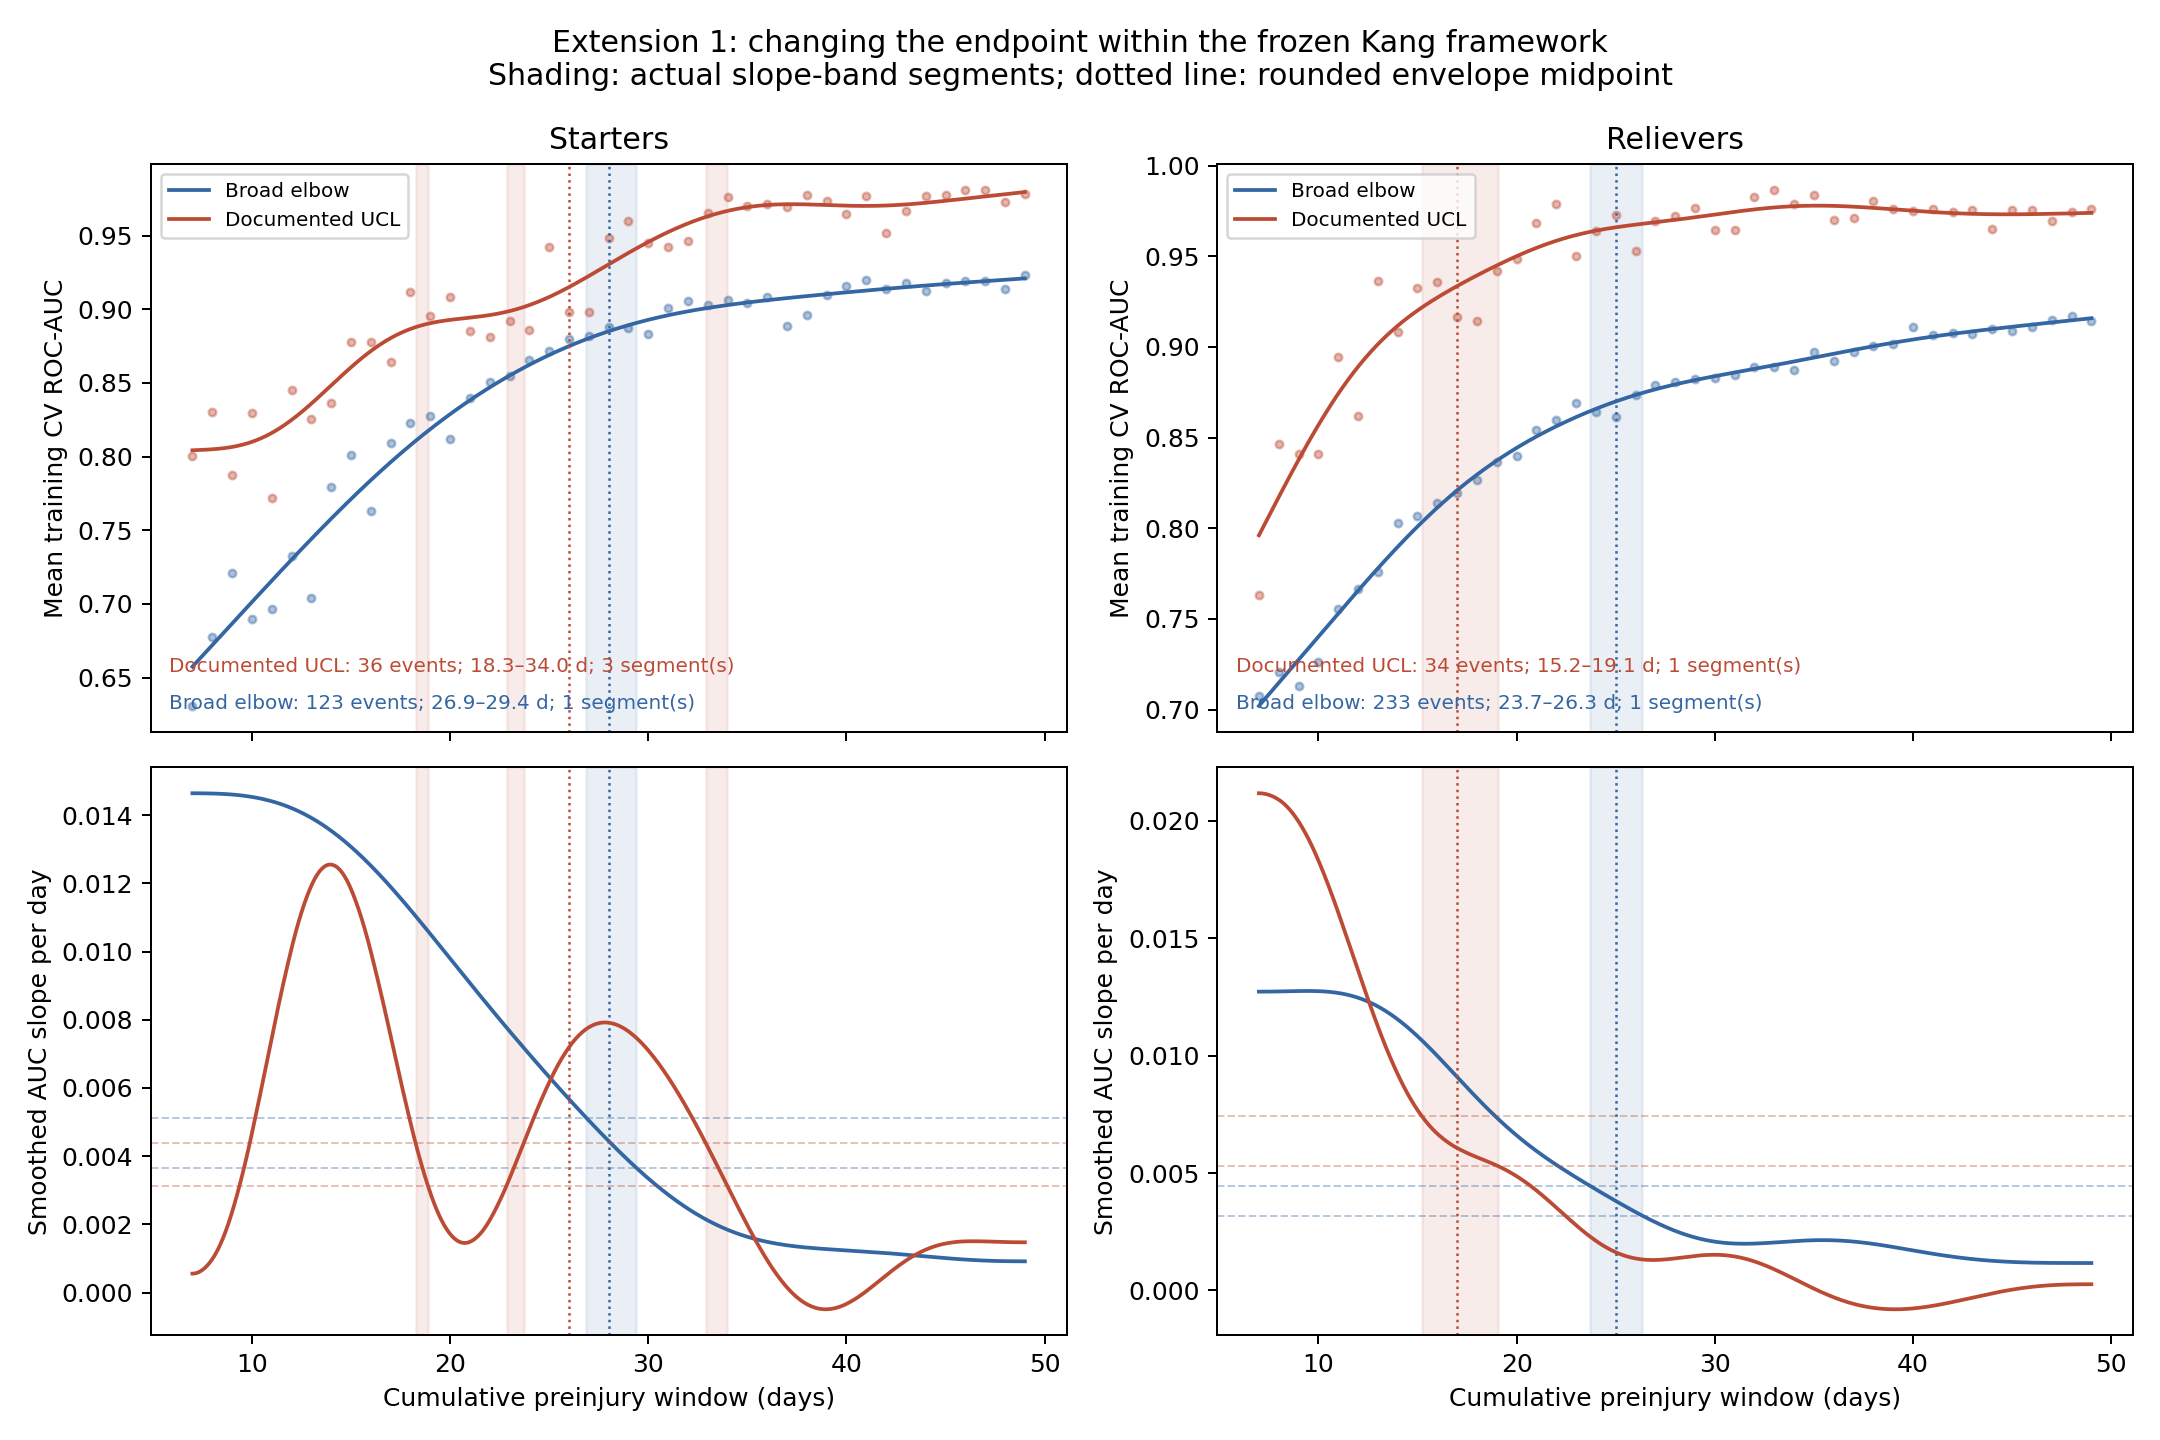

,window,cv_roc_auc,cv_fold_sd,folds,validation_games,validation_positive_games,outcome,role
0,7,0.630802,0.070451,5,23098,97,elbow,starter
1,8,0.677830,0.050576,5,23098,109,elbow,starter
2,9,0.720720,0.075577,5,23098,127,elbow,starter
3,10,0.689440,0.032118,5,23098,135,elbow,starter
4,11,0.696231,0.050300,5,23098,146,elbow,starter
...,...,...,...,...,...,...,...,...
167,45,0.975493,0.011248,5,76992,235,ucl,reliever
168,46,0.975493,0.011248,5,76992,235,ucl,reliever
169,47,0.969211,0.016420,5,76992,238,ucl,reliever
170,48,0.974274,0.015305,5,76992,241,ucl,reliever


,outcome,role,cohort_games,cohort_events,injured_pitchers,selected_window,band_lower,band_upper,band_segments,selected_day_in_band,...,features,roc_auc,ci_low,ci_high,valid_bootstraps,shared_pitchers,cohort_positive_games,cohort_prevalence,shared_positive_events,ucl_vs_elbow_window
0,elbow,starter,34477,123,106,28,26.88,29.39,1,True,...,18.0,0.9245,0.9048,0.9442,500.0,614.0,514,0.0149,99,ambiguous_or_unsupported
1,ucl,starter,33218,36,36,26,18.26,33.98,3,False,...,18.0,0.9559,0.9269,0.9877,500.0,587.0,163,0.0049,29,ambiguous_or_unsupported
2,elbow,reliever,119590,233,208,25,23.69,26.33,1,True,...,18.0,0.9097,0.8910,0.9256,500.0,1403.0,1661,0.0139,206,shorter
3,ucl,reliever,114915,34,34,17,15.23,19.06,1,True,...,18.0,0.9868,0.9797,0.9929,500.0,1373.0,190,0.0017,29,shorter


In [4]:
display(Image(filename=str(R/'figures/01_endpoint_window_comparison.png')))
display(pd.read_csv(T/'window_performance.csv'))
display(pd.read_csv(T/'primary_comparison.csv').round(4))

## Feature reliance within the same model family

The original 500 training pitcher-season refits estimate mean normalized total
Gain. Compare selected variables, common leading predictors and rank movement.
Unselected features have missing Gain, not evidence of a physiological null.
Correlated variables can trade importance. No causal interpretation is implied.

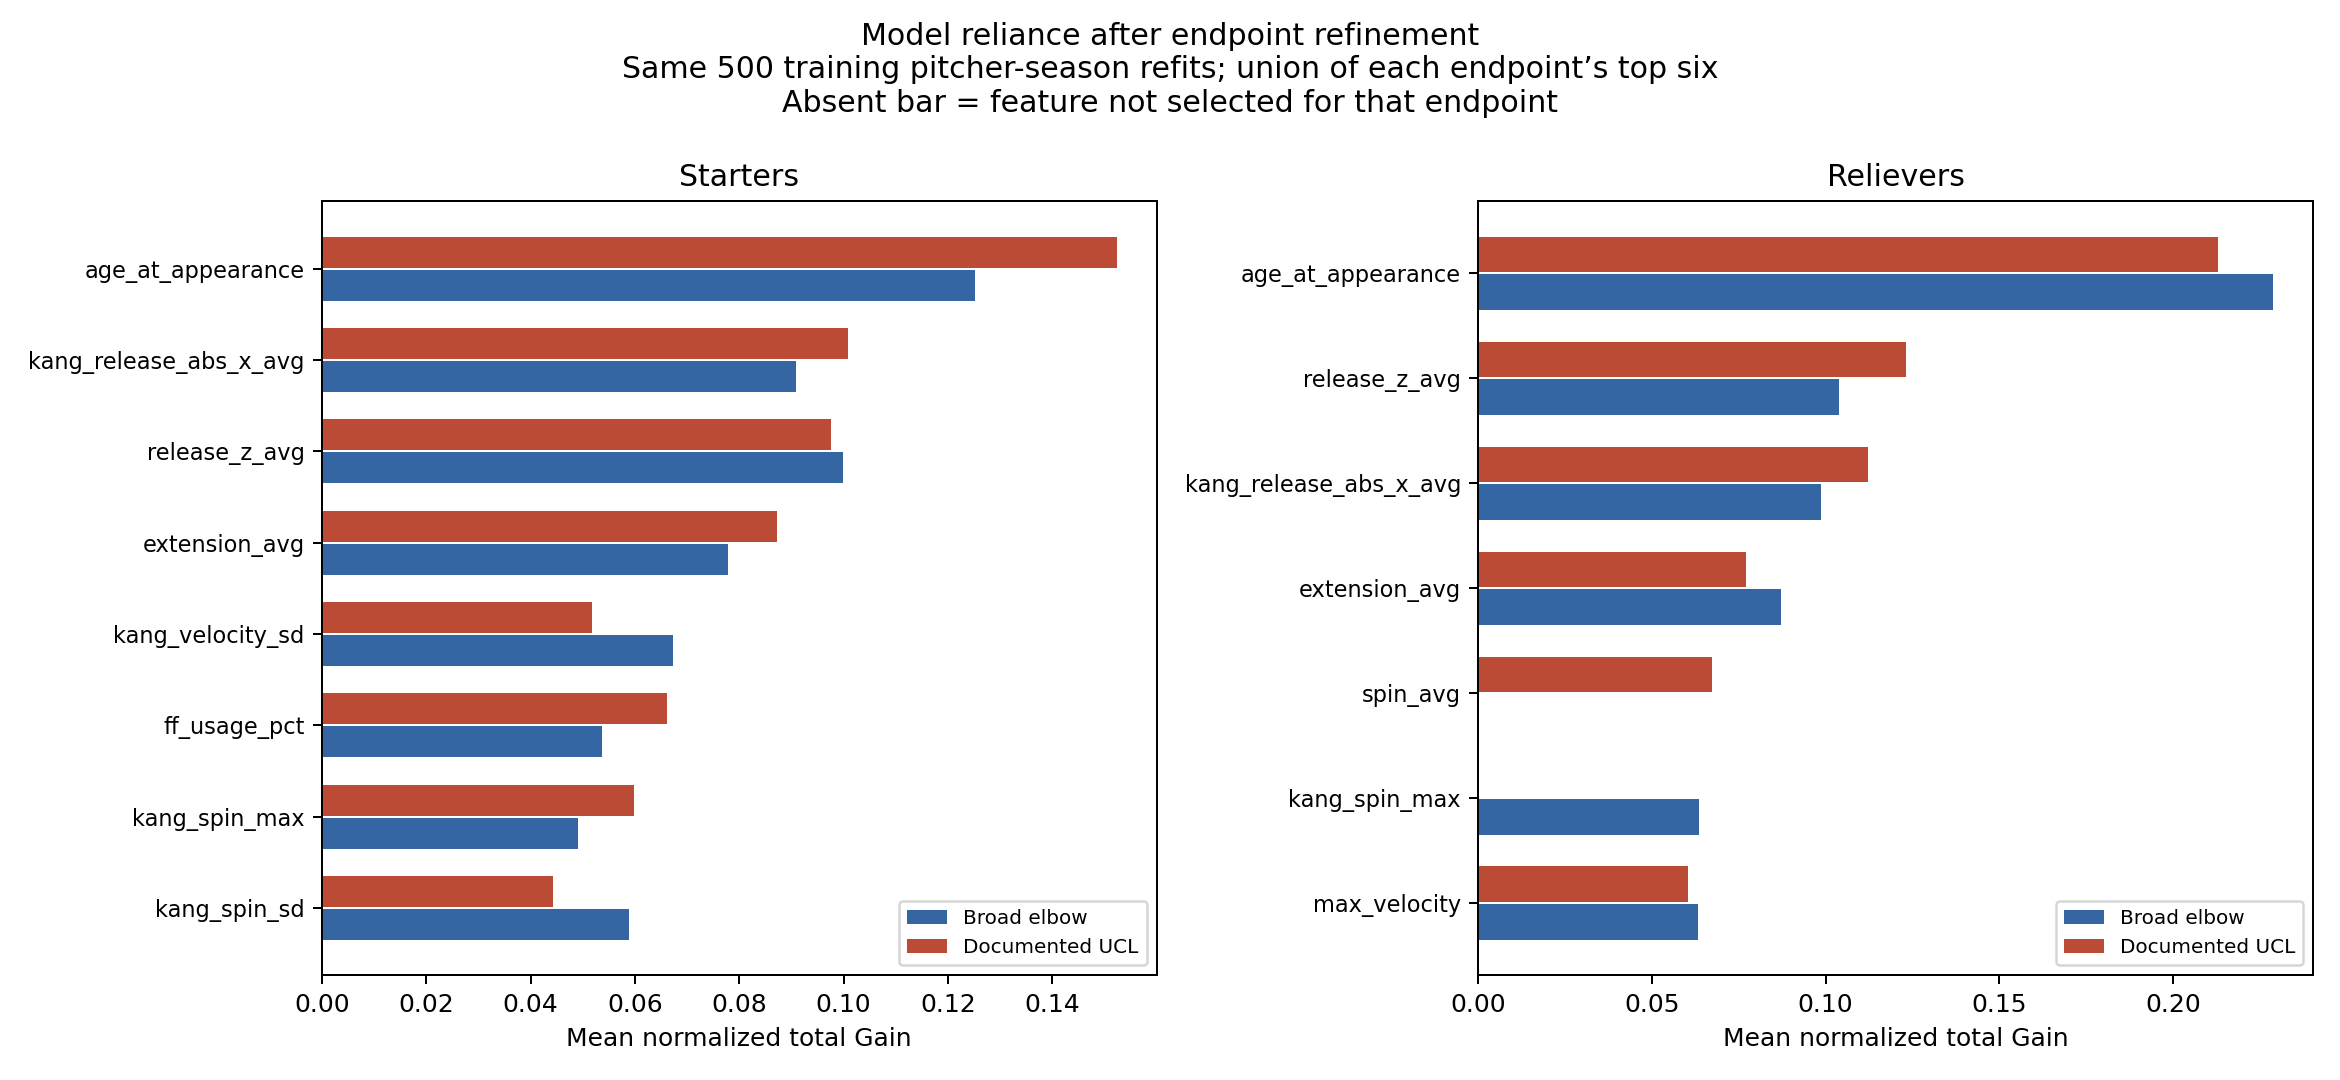

,feature,role,domain,elbow_rank,elbow_mean_gain,elbow_gain_sd,elbow_valid_refits,elbow_selected,ucl_rank,ucl_mean_gain,ucl_gain_sd,ucl_valid_refits,ucl_selected,rank_change_ucl_minus_elbow,selection_comparison
0,age_at_appearance,starter,context,1.0,0.125115,0.018843,500.0,True,1.0,0.152355,0.054638,500.0,True,0.0,both
1,total_pitches,starter,workload,15.0,0.039022,0.009565,500.0,True,16.0,0.019686,0.012836,500.0,True,1.0,both
2,innings_pitched,starter,workload,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,False,NaN,neither
3,batters_faced,starter,workload,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,False,NaN,neither
4,avg_velocity,starter,velocity,8.0,0.053766,0.012215,500.0,True,12.0,0.040044,0.019018,500.0,True,4.0,both
5,max_velocity,starter,velocity,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,False,NaN,neither
6,kang_velocity_sd,starter,velocity,5.0,0.067246,0.013396,500.0,True,8.0,0.051761,0.023932,500.0,True,3.0,both
7,spin_avg,starter,spin,7.0,0.057046,0.011975,500.0,True,10.0,0.049065,0.026928,500.0,True,3.0,both
8,kang_spin_max,starter,spin,10.0,0.049090,0.011338,500.0,True,6.0,0.059783,0.029953,500.0,True,-4.0,both
9,kang_spin_sd,starter,spin,6.0,0.058855,0.012432,500.0,True,11.0,0.044225,0.021742,500.0,True,5.0,both


,roc_auc,ci_low,ci_high,delta_auc,outcome,role
0,0.907114,0.883937,0.930083,-0.017392,elbow,starter
1,0.954796,0.922272,0.987522,-0.001079,ucl,starter
2,0.915547,0.901143,0.929377,0.005831,elbow,reliever
3,0.984187,0.970803,0.993242,-0.002640,ucl,reliever


In [5]:
display(Image(filename=str(R/'figures/02_endpoint_feature_importance.png')))
display(pd.read_csv(T/'feature_importance_comparison.csv'))
display(pd.read_csv(T/'prior_broad_elbow_history_supplement.csv'))

## Interpretation and limits

The random partition algorithm and seed are fixed; actual assignments can change
with endpoint labels and membership. Shared pitchers remain in train and test.
The contrast therefore includes changes in case composition, reference timing
and class weights induced by prevalence. It is neither a paired causal estimate
nor chronological or operational-warning validation. The source's retrospective
2026 retrieval/confirmation metadata do not enter predictors or select models.

Read the computed findings and preservation checks below. Extension 2 has not
been run.

In [6]:
display(pd.read_csv(T/'validation_checks.csv'))
display(Markdown((R/'summary.md').read_text()))

,role,status,independent_roc_auc,training_games,test_games,test_events,shared_pitchers,candidate_windows,selection_fits,importance_refits
0,starter,passed,0.955875,22255,10963,30,587,43,250,500
1,reliever,passed,0.986827,76992,37923,29,1373,43,250,500


# Extension 1 — UCL endpoint specificity

Completed comparison against the frozen Kang replication. Endpoint/adjudication and resulting case membership/reference dates changed; model, predictors, splitting algorithm, selection, window search and ROC-AUC procedure did not.

## Cohort and endpoint overlap

| outcome   | role     |   games |   pitcher_seasons |   unique_pitchers |   injury_events |   injured_pitchers |   control_games |   case_games |
|:----------|:---------|--------:|------------------:|------------------:|----------------:|-------------------:|----------------:|-------------:|
| elbow     | starter  |   34477 |              1665 |               620 |             123 |                106 |           32975 |         1502 |
| elbow     | reliever |  119590 |              3669 |              1418 |             233 |                208 |          114349 |         5241 |
| ucl       | starter  |   33218 |              1567 |               599 |              36 |                 36 |           32853 |          365 |
| ucl       | reliever |  114915 |              3466 |              1389 |              34 |                 34 |          114304 |          611 |

The benchmark contains **356 broad elbow events**. **55 (15.4%)** remain UCL cases. The same first-event rule also admits **15 confirmed forearm/UCL cases**, yielding **70 UCL events**. The established source contains 150 accepted 2017–2025 UCL events before benchmark eligibility/first-event filtering. Non-UCL elbow cases are excluded, not reclassified as healthy controls. The endpoint-overlap and all-source mapping tables give event-level reasons.

## Prevalence at the common 30-day candidate window

| outcome   | role     |   games |   positive_games |   negative_games |   prevalence |   represented_events |
|:----------|:---------|--------:|-----------------:|-----------------:|-------------:|---------------------:|
| elbow     | starter  |   34477 |              552 |            33925 |     0.016011 |                  120 |
| elbow     | reliever |  119590 |             1916 |           117674 |     0.016021 |                  230 |
| ucl       | starter  |   33218 |              186 |            33032 |     0.005599 |                   36 |
| ucl       | reliever |  114915 |              285 |           114630 |     0.00248  |                   34 |

This common existing candidate window describes class composition; it is not an additional window-selection rule. All 43 windows and earlier-case negatives appear in `tables/window_support.csv`.

## Selected-window results

| outcome   | role     |   cohort_events |   selected_window |   band_lower |   band_upper |   band_segments | selected_day_in_band   |   roc_auc |   ci_low |   ci_high |   test_events |   shared_positive_events |   features | ucl_vs_elbow_window      |
|:----------|:---------|----------------:|------------------:|-------------:|-------------:|----------------:|:-----------------------|----------:|---------:|----------:|--------------:|-------------------------:|-----------:|:-------------------------|
| elbow     | starter  |             123 |                28 |        26.88 |        29.39 |               1 | True                   |    0.9245 |   0.9048 |    0.9442 |           100 |                       99 |         18 | ambiguous_or_unsupported |
| ucl       | starter  |              36 |                26 |        18.26 |        33.98 |               3 | False                  |    0.9559 |   0.9269 |    0.9877 |            30 |                       29 |         18 | ambiguous_or_unsupported |
| elbow     | reliever |             233 |                25 |        23.69 |        26.33 |               1 | True                   |    0.9097 |   0.891  |    0.9256 |           208 |                      206 |         18 | shorter                  |
| ucl       | reliever |              34 |                17 |        15.23 |        19.06 |               1 | True                   |    0.9868 |   0.9797 |    0.9929 |            29 |                       29 |         18 | shorter                  |

**Starters:** UCL AUC 0.956 (95% cluster interval 0.927–0.988), versus elbow 0.925; higher by 0.031. Selected integer window 26 days; band 18.26–33.98 (3 segment(s), midpoint in band: False). Window relation: ambiguous_or_unsupported. 30 UCL events contribute positive held-out games.

Shared top-five predictors: age_at_appearance, kang_release_abs_x_avg, release_z_avg, extension_avg. Rank changes (positive = lower UCL rank): avg_velocity (+4 ranks), kang_velocity_sd (+3 ranks), spin_avg (+3 ranks), kang_spin_max (-4 ranks), kang_spin_sd (+5 ranks), ff_usage_pct (-4 ranks), st_usage_pct (-10 ranks), ch_usage_pct (+3 ranks). Newly selected: none. No longer selected: none.

**Relievers:** UCL AUC 0.987 (95% cluster interval 0.980–0.993), versus elbow 0.910; higher by 0.077. Selected integer window 17 days; band 15.23–19.06 (1 segment(s), midpoint in band: True). Window relation: shorter. 29 UCL events contribute positive held-out games.

Shared top-five predictors: age_at_appearance, kang_release_abs_x_avg, release_z_avg, extension_avg. Rank changes (positive = lower UCL rank): none with a ≥3-rank shift among shared selected features. Newly selected: spin_avg. No longer selected: kang_spin_max.

The intervals on ROC-AUC use the same 500 held-out pitcher-season resamples as the benchmark. The slope bands are not confidence intervals. A disconnected envelope or midpoint outside the band does not establish a unique optimal preinjury window.

## Interpretation and decision

Ranking signal persists for both roles under the same random-game design: both UCL AUC intervals exceed 0.5. This is conditional discrimination, not evidence of ahead-of-time clinical usefulness or generalization to future seasons.

Higher or lower AUC is not automatically improvement or deterioration of a warning system. Fewer and different cases, their timing, prevalence-derived class weights and changed random-game membership all accompany the endpoint change. No paired significance test or operational-warning claim is made. Gain describes model reliance, not tissue damage or causation.

The reduced independent-event count limits precision and makes feature ranks/window shapes sensitive to case composition. Shared pitchers across random train/test games remain intentional. Broad-control unknown diagnoses remain as in the benchmark. The source is retrospective operational adjudication, not an independent clinical review.

The primary table also reports injury events with positive games in **both** training and test. The held-out games are not held-out injury events. Strong AUC can therefore reflect recognizable pitcher/event context; these results cannot isolate short-term warning information from persistent profile information.

There is enough technical support to specify **Extension 2: chronological validation**, with event-support checks and the present benchmark frozen. These random-game findings do not predict that chronological performance will persist. Do not tune this endpoint experiment to make that later comparison favorable. Extension 2 has not been run.

## Reproducibility

The original R script is reused without edits. `experiment_freeze.json` hashes all benchmark artifacts and the authoritative endpoint. `tables/benchmark_equivalence.csv` verifies fixed settings; `tables/validation_checks.csv` independently verifies labels, splits and AUC. Only the two UCL model tasks are fitted. The automatic prior-broad-elbow-history sensitivity is supplemental and never used for selection.

See [methods](../../docs/kang_ucl_endpoint_methods.md), [configuration](../../config/kang_ucl_endpoint.yaml), [window figure](figures/01_endpoint_window_comparison.png), [importance figure](figures/02_endpoint_feature_importance.png), [primary table](tables/primary_comparison.csv), and [importance comparison](tables/feature_importance_comparison.csv).
